# 04 · Classic Machine-Learning Baselines
## Kenyan Sign Language (KSL) Recognition with Deep Learning

| | |
|---|---|
| **Course** | DSA 4050-XA: Deep Learning, USIU-Africa (Fall 2026) |
| **Student** | Selmah Tzindori (669602) |
| **Notebook** | `04_classic_ml.ipynb` |
| **Term paper part** | (c) Undertake ML algorithms (consider accuracy) and test various ML training |

### Objective
Establish how well **classic machine learning** recognises KSL signs, so that the deep-learning models in notebook 05 have a fair benchmark to beat. Classic models cannot read raw photos directly; they need the image turned into a fixed list of numbers (**features**) first. We test two feature types with four algorithms.

### Inputs
- `data/processed/ksl_224.zip` and `catalogue_split.csv` (from notebook 03)

### Outputs
| File | Location | Purpose |
|---|---|---|
| 8 rows in `experiments.csv` | `outputs/` | Accuracy and macro-F1 of every feature × model combination |
| `04_*.png`, `04_*.csv` | `outputs/` | HOG illustration, tuning results, comparison chart, confusion matrix |
| `classic_best.pkl` | `models/` | The best classic model, for the final comparison and dashboard |

## 0 · Setup

In [1]:
# =============================================================================
# STANDARD SETUP CELL
# =============================================================================
from google.colab import drive
drive.mount("/content/drive")

import sys
sys.path.insert(0, "/content/drive/MyDrive/DSA4050/ksl-recognition/src")

import importlib
import ksl_utils as ku
importlib.reload(ku)
ku.set_seed()

NOTEBOOK = "04_classic_ml"
PATHS = ku.PATHS
print("Project root:", ku.PROJECT_ROOT)

Mounted at /content/drive
Random seed set to 42
Project root: /content/drive/MyDrive/DSA4050/ksl-recognition


In [2]:
# Libraries used in this notebook
import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from PIL import Image
from tqdm.auto import tqdm
from skimage.feature import hog

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 11})

In [3]:
# Restore the 224x224 images and load the split catalogue
PROC_DIR = Path(ku.restore_processed_data())
cat = ku.load_split_catalogue()
CLASS_NAMES = ku.load_class_names()
print(cat["split"].value_counts().reindex(["train", "val", "test"]).to_string())

Processed data restored to /content/ksl_224 in 7s
split
train    4362
val       935
test      941


## 1 · Load the images as small greyscale arrays
Classic models work best on compact inputs, so each 224×224 image is converted to **greyscale** and shrunk:
- **64×64** for HOG features (enough detail for hand edges)
- **32×32** for the raw-pixel features (1,024 numbers per image)

Colour is dropped on purpose: notebook 02 showed colour mostly reflects clothing and background, not the sign.

In [4]:
def load_grey(file: str, size: int) -> np.ndarray:
    """Open a processed image, convert to greyscale, resize, and scale pixel values to 0-1."""
    with Image.open(PROC_DIR / file) as img:
        return np.asarray(img.convert("L").resize((size, size), Image.Resampling.BILINEAR),
                          dtype=np.float32) / 255.0

X64 = np.stack([load_grey(f, 64) for f in tqdm(cat["proc_file"], desc="Loading 64x64")])
X32 = np.stack([load_grey(f, 32) for f in tqdm(cat["proc_file"], desc="Loading 32x32")])
y = cat["label_idx"].to_numpy()

# Boolean masks for the three sets (same split as every other notebook)
is_train = (cat["split"] == "train").to_numpy()
is_val = (cat["split"] == "val").to_numpy()
is_test = (cat["split"] == "test").to_numpy()
print("64x64 array:", X64.shape, "| 32x32 array:", X32.shape)

Loading 64x64:   0%|          | 0/6238 [00:00<?, ?it/s]

Loading 32x32:   0%|          | 0/6238 [00:00<?, ?it/s]

64x64 array: (6238, 64, 64) | 32x32 array: (6238, 32, 32)


## 2 · Build the two feature sets

| Feature set | How it is made | Size per image |
|---|---|---|
| **Raw pixels** | The 32×32 greyscale image flattened into one long list | 1,024 |
| **HOG** (Histogram of Oriented Gradients) | The 64×64 image is divided into 8×8-pixel cells; each cell records **which directions its edges point** (9 direction bins), normalised over neighbouring blocks. It captures the *outline* of hands and arms while ignoring flat colour and brightness. | 1,764 |

HOG was a leading hand-crafted feature for gesture and person recognition before deep learning, which makes it a fair and well-established baseline.

In [5]:
def hog_features(img: np.ndarray) -> np.ndarray:
    """HOG descriptor: 9 orientation bins, 8x8-pixel cells, 2x2-cell blocks."""
    return hog(img, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2),
               block_norm="L2-Hys", feature_vector=True)

start = time.time()
F_hog = np.stack([hog_features(im) for im in tqdm(X64, desc="HOG")]).astype(np.float32)
F_raw = X32.reshape(len(X32), -1)
print(f"Raw pixels: {F_raw.shape} | HOG: {F_hog.shape} | HOG time {time.time() - start:.0f}s")

FEATURES = {"raw_pixels": F_raw, "hog": F_hog}

HOG:   0%|          | 0/6238 [00:00<?, ?it/s]

Raw pixels: (6238, 1024) | HOG: (6238, 1764) | HOG time 10s


### 2.1 · What HOG "sees"
For one example per sign: the greyscale image and its HOG visualisation (brighter strokes = stronger edges in that direction).

Figure saved -> /content/drive/MyDrive/DSA4050/ksl-recognition/outputs/figures/04_hog_examples.png


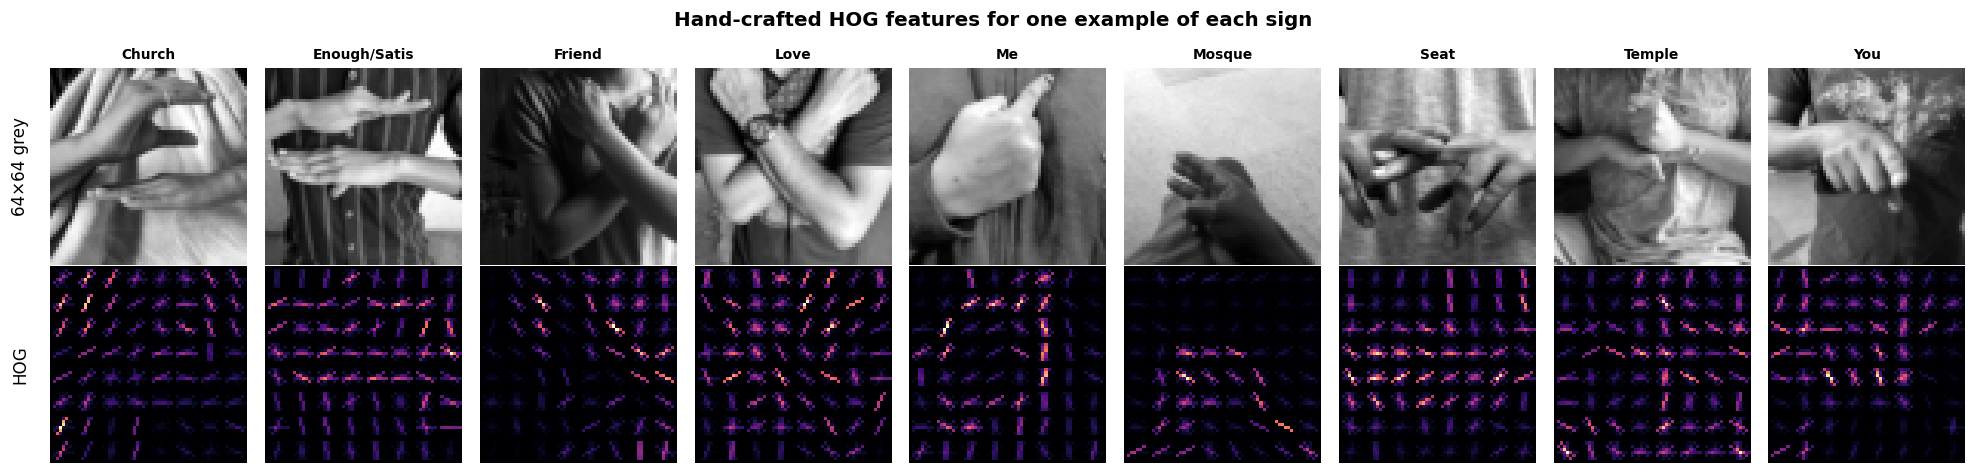

In [6]:
sample = cat.groupby("label").sample(1, random_state=ku.SEED).sort_values("label_idx")
fig, axes = plt.subplots(2, len(sample), figsize=(2 * len(sample), 4.4))
for c, (i, row) in enumerate(sample.iterrows()):
    img = X64[i]
    _, hog_img = hog(img, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), visualize=True)
    axes[0, c].imshow(img, cmap="gray")
    axes[1, c].imshow(hog_img, cmap="magma")
    axes[0, c].set_title(row["label"][:12], fontsize=9)
    for r in range(2):
        axes[r, c].axis("off")
axes[0, 0].text(-0.2, 0.5, "64×64 grey", transform=axes[0, 0].transAxes, rotation=90, va="center")
axes[1, 0].text(-0.2, 0.5, "HOG", transform=axes[1, 0].transAxes, rotation=90, va="center")
fig.suptitle("Hand-crafted HOG features for one example of each sign", fontsize=13, fontweight="bold")
fig.tight_layout()
ku.save_figure(fig, "04_hog_examples", NOTEBOOK, caption="Greyscale input and HOG edge-orientation features for each sign.")
plt.show()

**Interpretation:** HOG keeps the outline of the arms and hands but also every edge from clothing patterns, folds and background. The classifier then has to work out which edges matter, which is hard when patterned shirts produce stronger edges than the hands themselves.

## 3 · Four classic algorithms
Each feature set is first **standardised** (mean 0, variance 1) and compressed with **PCA to 150 components**, which keeps most of the information while making training fast and reducing noise. The same preparation is used for every model, so differences come from the algorithms.

| Model | Idea | Settings tried |
|---|---|---|
| **Logistic Regression** | Linear boundaries between classes | regularisation C ∈ {0.01, 0.1, 1} |
| **SVM (RBF kernel)** | Flexible, curved boundaries via a kernel | C ∈ {1, 10} |
| **Random Forest** | Many decision trees voting | max depth ∈ {None, 20}, 300 trees |
| **k-Nearest Neighbours** | Label of the most similar training images | k ∈ {3, 7, 15} |

**Tuning procedure:** every setting is trained on the **training set** and scored on the **validation set**; the best setting is kept and then evaluated **once** on the **test set**. The test set plays no part in any choice.

In [7]:
N_PCA = 150

def make_model(name: str, param):
    """Standardise -> PCA(150) -> classifier."""
    if name == "logreg":
        clf = LogisticRegression(C=param, max_iter=2000)
    elif name == "svm_rbf":
        clf = SVC(C=param, kernel="rbf", gamma="scale", probability=True, random_state=ku.SEED)
    elif name == "random_forest":
        clf = RandomForestClassifier(n_estimators=300, max_depth=param, n_jobs=-1, random_state=ku.SEED)
    elif name == "knn":
        clf = KNeighborsClassifier(n_neighbors=param, n_jobs=-1)
    return make_pipeline(StandardScaler(), PCA(n_components=N_PCA, random_state=ku.SEED), clf)

GRID = {"logreg": [0.01, 0.1, 1.0],
        "svm_rbf": [1.0, 10.0],
        "random_forest": [None, 20],
        "knn": [3, 7, 15]}
PARAM_NAME = {"logreg": "C", "svm_rbf": "C", "random_forest": "max_depth", "knn": "k"}

In [8]:
tuning_rows = []
best = {}   # (feature, model) -> best param + validation accuracy

for feat_name, F in FEATURES.items():
    for model_name, params in GRID.items():
        for p in params:
            start = time.time()
            model = make_model(model_name, p).fit(F[is_train], y[is_train])
            fit_s = time.time() - start
            val_acc = accuracy_score(y[is_val], model.predict(F[is_val]))
            tuning_rows.append({"features": feat_name, "model": model_name,
                                "setting": f"{PARAM_NAME[model_name]}={p}",
                                "val_accuracy": round(val_acc, 4), "fit_time_s": round(fit_s, 1)})
            print(f"{feat_name:<11} {model_name:<14} {PARAM_NAME[model_name]}={str(p):<5} "
                  f"val acc = {val_acc:.3f}  ({fit_s:.0f}s)")
            key = (feat_name, model_name)
            if key not in best or val_acc > best[key]["val_acc"]:
                best[key] = {"param": p, "val_acc": val_acc}

tuning = pd.DataFrame(tuning_rows)
ku.save_table(tuning, "04_tuning_results", NOTEBOOK,
              caption="Validation accuracy for every feature set, model and setting tried.")

raw_pixels  logreg         C=0.01  val acc = 0.181  (3s)
raw_pixels  logreg         C=0.1   val acc = 0.172  (2s)
raw_pixels  logreg         C=1.0   val acc = 0.174  (2s)
raw_pixels  svm_rbf        C=1.0   val acc = 0.361  (21s)
raw_pixels  svm_rbf        C=10.0  val acc = 0.379  (25s)
raw_pixels  random_forest  max_depth=None  val acc = 0.307  (26s)
raw_pixels  random_forest  max_depth=20    val acc = 0.306  (22s)
raw_pixels  knn            k=3     val acc = 0.252  (1s)
raw_pixels  knn            k=7     val acc = 0.276  (2s)
raw_pixels  knn            k=15    val acc = 0.305  (1s)
hog         logreg         C=0.01  val acc = 0.540  (3s)
hog         logreg         C=0.1   val acc = 0.537  (3s)
hog         logreg         C=1.0   val acc = 0.534  (2s)
hog         svm_rbf        C=1.0   val acc = 0.617  (16s)
hog         svm_rbf        C=10.0  val acc = 0.634  (22s)
hog         random_forest  max_depth=None  val acc = 0.565  (19s)
hog         random_forest  max_depth=20    val acc = 0.56

'/content/drive/MyDrive/DSA4050/ksl-recognition/outputs/tables/04_tuning_results.csv'

## 4 · Final evaluation on the test set
Each feature × model pair is refitted on the training set with its best setting and evaluated **once** on the test set.

- **Accuracy:** share of test images classified correctly.
- **Macro-F1:** the F1-score (balance of precision and recall) averaged equally over the 9 signs, so every sign counts the same.

In [9]:
results = []
fitted = {}

for (feat_name, model_name), b in best.items():
    F = FEATURES[feat_name]
    start = time.time()
    model = make_model(model_name, b["param"]).fit(F[is_train], y[is_train])
    fit_s = time.time() - start

    start = time.time()
    pred = model.predict(F[is_test])
    pred_ms = 1000 * (time.time() - start) / is_test.sum()      # milliseconds per image

    row = {"features": feat_name, "model": model_name,
           "best_setting": f"{PARAM_NAME[model_name]}={b['param']}",
           "train_accuracy": accuracy_score(y[is_train], model.predict(F[is_train])),
           "val_accuracy": b["val_acc"],
           "test_accuracy": accuracy_score(y[is_test], pred),
           "test_macro_f1": f1_score(y[is_test], pred, average="macro"),
           "fit_time_s": fit_s, "predict_ms_per_image": pred_ms}
    results.append(row)
    fitted[(feat_name, model_name)] = (model, pred)

    # One row per model in experiments.csv: the project-wide comparison table
    ku.log_experiment(f"{feat_name}+{model_name}", "classic_ml",
                      {k: round(float(row[k]), 4) for k in
                       ["train_accuracy", "val_accuracy", "test_accuracy", "test_macro_f1",
                        "fit_time_s", "predict_ms_per_image"]},
                      NOTEBOOK, params={PARAM_NAME[model_name]: b["param"], "pca": N_PCA})

results = pd.DataFrame(results).sort_values("test_accuracy", ascending=False).reset_index(drop=True)
ku.save_table(results.round(4), "04_classic_results", NOTEBOOK,
              caption="Test performance of classic machine-learning models (best setting per model).")
results.round(3)

Experiment logged: raw_pixels+logreg -> {'train_accuracy': 0.2799, 'val_accuracy': 0.1807, 'test_accuracy': 0.2062, 'test_macro_f1': 0.203, 'fit_time_s': 1.5708, 'predict_ms_per_image': 0.0219}
Experiment logged: raw_pixels+svm_rbf -> {'train_accuracy': 0.9968, 'val_accuracy': 0.3786, 'test_accuracy': 0.3496, 'test_macro_f1': 0.3516, 'fit_time_s': 25.9071, 'predict_ms_per_image': 1.0718}
Experiment logged: raw_pixels+random_forest -> {'train_accuracy': 1.0, 'val_accuracy': 0.307, 'test_accuracy': 0.2678, 'test_macro_f1': 0.2623, 'fit_time_s': 25.8287, 'predict_ms_per_image': 0.1565}
Experiment logged: raw_pixels+knn -> {'train_accuracy': 0.3888, 'val_accuracy': 0.3048, 'test_accuracy': 0.2752, 'test_macro_f1': 0.271, 'fit_time_s': 0.5804, 'predict_ms_per_image': 0.1534}
Experiment logged: hog+logreg -> {'train_accuracy': 0.6238, 'val_accuracy': 0.5401, 'test_accuracy': 0.5228, 'test_macro_f1': 0.5238, 'fit_time_s': 2.5425, 'predict_ms_per_image': 0.0236}
Experiment logged: hog+svm_rbf 

,features,model,best_setting,train_accuracy,val_accuracy,test_accuracy,test_macro_f1,fit_time_s,predict_ms_per_image
0,hog,svm_rbf,C=10.0,1.000,0.634,0.600,0.603,19.985,1.350
1,hog,knn,k=15,0.643,0.584,0.558,0.558,1.249,0.130
2,hog,logreg,C=0.01,0.624,0.540,0.523,0.524,2.543,0.024
3,hog,random_forest,max_depth=None,1.000,0.565,0.518,0.516,19.252,0.155
4,raw_pixels,svm_rbf,C=10.0,0.997,0.379,0.350,0.352,25.907,1.072
5,raw_pixels,knn,k=15,0.389,0.305,0.275,0.271,0.580,0.153
6,raw_pixels,random_forest,max_depth=None,1.000,0.307,0.268,0.262,25.829,0.156
7,raw_pixels,logreg,C=0.01,0.280,0.181,0.206,0.203,1.571,0.022


Figure saved -> /content/drive/MyDrive/DSA4050/ksl-recognition/outputs/figures/04_classic_accuracy.png


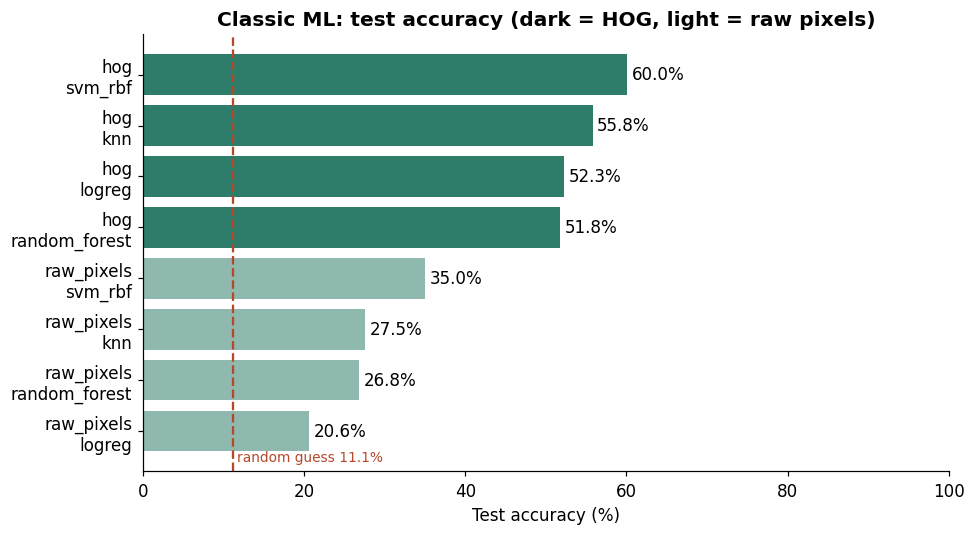

In [10]:
# Chart: test accuracy of each combination vs the random-guess baseline
baseline = 1 / len(CLASS_NAMES)
plot = results.assign(name=results["features"] + "\n" + results["model"]).sort_values("test_accuracy")

fig, ax = plt.subplots(figsize=(9, 5))
colours = ["#2E7D6B" if f == "hog" else "#8FB9AE" for f in plot["features"]]
bars = ax.barh(plot["name"], plot["test_accuracy"] * 100, color=colours)
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in plot["test_accuracy"] * 100], padding=3)
ax.axvline(baseline * 100, color="#B5482B", linestyle="--")
ax.text(baseline * 100 + 0.5, -0.6, f"random guess {baseline:.1%}", color="#B5482B", fontsize=9)
ax.set_xlim(0, 100)
ax.set_xlabel("Test accuracy (%)")
ax.set_title("Classic ML: test accuracy (dark = HOG, light = raw pixels)")
fig.tight_layout()
ku.save_figure(fig, "04_classic_accuracy", NOTEBOOK, caption="Test accuracy of classic ML models against the random-guess baseline.")
plt.show()

**Interpretation:**
- **HOG beats raw pixels with every algorithm**, by 20–32 percentage points (e.g. SVM: 60.0% vs 35.0%). Describing edge directions is far more useful than raw brightness values, which change with lighting, skin tone and clothing.
- The **best combination, HOG + SVM (RBF, C = 10), reaches 60.0% test accuracy** (macro-F1 0.603), about **5.4× the 11.1% random baseline**, but it still gets **4 in 10 signs wrong**.
- **Overfitting:** SVM and Random Forest reach **100% training accuracy** but only 52–60% on the test set, so they memorise the training photos rather than learning the sign. The linear model (Logistic Regression) does not overfit (62% train) but cannot fit the patterns well (52% test).
- Raw-pixel Logistic Regression (20.6%) barely beats random guessing, which shows that the classes **cannot be separated by simple linear combinations of pixels**.

## 5 · Where does the best classic model go wrong?
The best classic model is the one with the **highest validation accuracy** (choosing by test accuracy would let the test set influence a decision). The **confusion matrix** shows, for each true sign (row), the share of test images predicted as each sign (column). The diagonal is the share correct; off-diagonal cells reveal which signs get mixed up.

Best classic model: hog + svm_rbf (C=10.0), test accuracy 0.600
Figure saved -> /content/drive/MyDrive/DSA4050/ksl-recognition/outputs/figures/04_confusion_best_classic.png


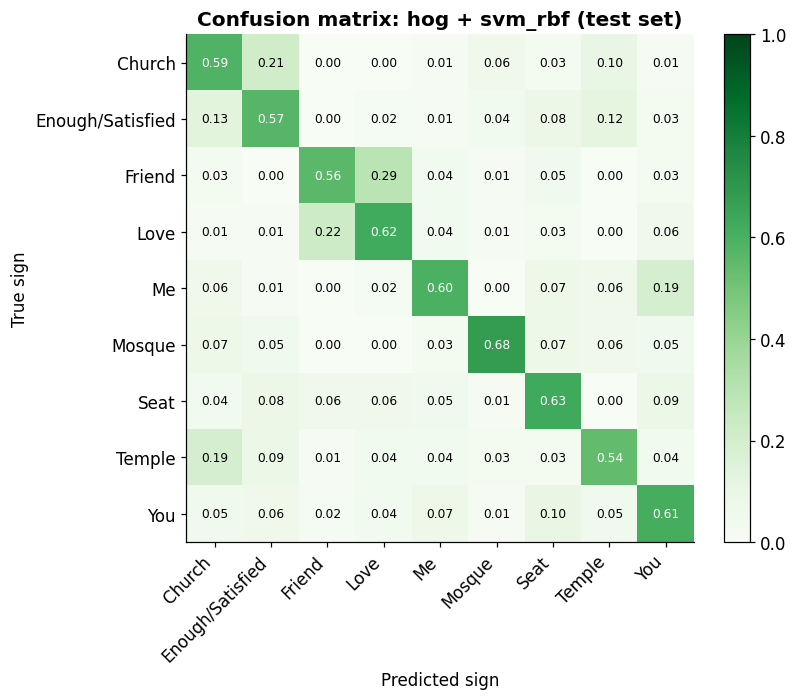

In [11]:
# The "best" model is chosen by VALIDATION accuracy (ties -> higher validation macro-F1 is not
# available, so the faster prediction wins); the test set is only used to report the result.
best_row = results.sort_values(["val_accuracy", "predict_ms_per_image"], ascending=[False, True]).iloc[0]
best_key = (best_row["features"], best_row["model"])
best_model, best_pred = fitted[best_key]
print(f"Best classic model: {best_key[0]} + {best_key[1]} ({best_row['best_setting']}), "
      f"test accuracy {best_row['test_accuracy']:.3f}")

cm = confusion_matrix(y[is_test], best_pred, normalize="true")
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(cm, cmap="Greens", vmin=0, vmax=1)
ax.set_xticks(range(len(CLASS_NAMES)), CLASS_NAMES, rotation=45, ha="right")
ax.set_yticks(range(len(CLASS_NAMES)), CLASS_NAMES)
for i in range(len(CLASS_NAMES)):
    for j in range(len(CLASS_NAMES)):
        ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if cm[i, j] > 0.5 else "black")
ax.set_xlabel("Predicted sign")
ax.set_ylabel("True sign")
ax.set_title(f"Confusion matrix: {best_key[0]} + {best_key[1]} (test set)")
fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()
ku.save_figure(fig, "04_confusion_best_classic", NOTEBOOK, caption="Normalised confusion matrix of the best classic model on the test set.")
plt.show()

In [12]:
# Per-sign precision, recall and F1 for the best classic model
report = pd.DataFrame(classification_report(y[is_test], best_pred, target_names=CLASS_NAMES,
                                            output_dict=True)).T.round(3)
per_class = report.loc[CLASS_NAMES, ["precision", "recall", "f1-score", "support"]]
ku.save_table(per_class.reset_index(names="sign"), "04_per_class_best_classic", NOTEBOOK,
              caption="Per-sign precision, recall and F1 of the best classic model.")

# Most confused pairs (largest off-diagonal shares)
off = pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).stack()
off = off[[a != b for a, b in off.index]].sort_values(ascending=False).head(5)
print("Most common confusions (true -> predicted):")
for (t, p), v in off.items():
    print(f"  {t:<17} -> {p:<17} {v:.0%}")
per_class

Table saved  -> /content/drive/MyDrive/DSA4050/ksl-recognition/outputs/tables/04_per_class_best_classic.csv
Most common confusions (true -> predicted):
  Friend            -> Love              29%
  Love              -> Friend            22%
  Church            -> Enough/Satisfied  21%
  Me                -> You               19%
  Temple            -> Church            19%


,precision,recall,f1-score,support
Church,0.504,0.587,0.542,104.0
Enough/Satisfied,0.536,0.571,0.553,105.0
Friend,0.648,0.562,0.602,105.0
Love,0.571,0.621,0.595,103.0
Me,0.685,0.600,0.640,105.0
Mosque,0.807,0.683,0.740,104.0
Seat,0.584,0.629,0.606,105.0
Temple,0.588,0.543,0.564,105.0
You,0.557,0.610,0.582,105.0


**Interpretation:** the mistakes follow the **look-alike groups found in the EDA**:
- ***Friend → Love* (29%)** and ***Love → Friend* (22%)**: both cross the arms over the chest; they differ only in open hands vs fists, a detail HOG at 64×64 struggles to capture.
- ***Church → Enough/Satisfied* (21%)** and ***Temple → Church* (19%)**: all use flat, horizontal hands in front of the body.
- ***Me → You* (19%)**: both are a single hand with a pointing finger near the chest.

***Mosque*** is the easiest sign (F1 0.74) and ***Church*** the hardest (F1 0.54). Telling these signs apart needs finer hand-shape detail (finger positions, open vs closed hands), which motivates models that learn their own features: convolutional neural networks.

## 6 · Save the best classic model and key results
The best model (the whole pipeline: scaler → PCA → classifier) is saved to Drive so the final comparison and the dashboard can reuse it.

In [13]:
joblib.dump({"pipeline": best_model, "features": best_key[0], "class_names": CLASS_NAMES,
             "input": "greyscale 64x64 -> HOG" if best_key[0] == "hog" else "greyscale 32x32 -> raw pixels"},
            ku.model_path("classic_best", "pkl"))
print("Saved:", ku.model_path("classic_best", "pkl"))

ku.log_result("best_classic_model", f"{best_key[0]}+{best_key[1]}", NOTEBOOK)
ku.log_result("best_classic_test_accuracy", round(float(best_row["test_accuracy"]), 4), NOTEBOOK)
ku.log_result("best_classic_test_macro_f1", round(float(best_row["test_macro_f1"]), 4), NOTEBOOK)

Saved: /content/drive/MyDrive/DSA4050/ksl-recognition/models/classic_best.pkl
Result logged: best_classic_model = hog+svm_rbf
Result logged: best_classic_test_accuracy = 0.6004
Result logged: best_classic_test_macro_f1 = 0.6026


## Check · Project status

In [14]:
ku.project_summary()

Project root : /content/drive/MyDrive/DSA4050/ksl-recognition
Figures      : 15
Tables       : 13
Models       : 1
Results      : 41
Experiments  : 8


## Findings for the report
- **Setup:** 2 feature sets (raw 32×32 pixels; HOG edge-orientation features from 64×64 greyscale) × 4 algorithms (Logistic Regression, SVM-RBF, Random Forest, k-NN), each standardised and reduced with PCA (150 components), tuned on the validation set and evaluated once on the test set.
- **Best classic model: HOG + SVM (C = 10): 60.0% test accuracy, macro-F1 0.603**, 5.4× the random baseline (11.1%).
- **Features matter more than the algorithm:** HOG beats raw pixels by 20–32 points for every model; the best raw-pixel model reaches only 35.0%.
- **Overfitting:** SVM and Random Forest score 100% on training data but 52–60% on test data, so hand-crafted features do not generalise across signers, clothing and backgrounds.
- **Errors follow the visual look-alikes:** *Friend ↔ Love* (29% / 22%), *Church → Enough/Satisfied* (21%), *Temple → Church* (19%), *Me → You* (19%). *Mosque* is easiest (F1 0.74), *Church* hardest (F1 0.54).
- **Motivation for deep learning:** distinguishing these signs needs fine hand-shape cues (open vs closed hands, finger positions) that fixed features miss; CNNs learn such features directly from the images.

**Next notebook:** `05_deep_learning.ipynb`: a CNN trained from scratch and pretrained models (transfer learning).